# Chapitre 2 - Exercices 2.6 à 2.9

Ce notebook traite les quatre derniers exercices du chapitre 2 :

- **2.6** : observations ex-aequo et moindres carrés pondérés réduits ;
- **2.7** : estimateurs linéaires en $y$, biais et variance conditionnels / non conditionnels ;
- **2.8** : régression linéaire contre $k$-ppv sur les chiffres manuscrits 2 et 3 ;
- **2.9** : l'erreur d'apprentissage sous-estime en moyenne l'erreur de test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## Exercice 2.6 : Ex-aequo et moindres carrés pondérés

**Énoncé (reformulé).** On considère un problème de régression d'entrées $x_i$ et de
sorties $y_i$, et un modèle paramétré $f_\theta(x)$ ajusté par moindres carrés. Montrer
que si plusieurs observations ont la **même valeur** de $x$ (ex-aequo), l'ajustement
peut être obtenu à partir d'un problème de **moindres carrés pondérés réduit**.

**Notations.** Notons $u_1, \dots, u_J$ les valeurs **distinctes** prises par les $x_i$,
$I_j = \{i : x_i = u_j\}$ l'ensemble des indices correspondants, $N_j = |I_j|$ leur nombre
(avec $\sum_j N_j = N$) et $\bar y_j = \frac1{N_j}\sum_{i\in I_j}y_i$ la moyenne des réponses
associées à $u_j$.

**Solution.** On regroupe les termes de la somme des carrés selon la valeur de $x$ :
$$\mathrm{RSS}(\theta) = \sum_{i=1}^N\big(y_i - f_\theta(x_i)\big)^2 = \sum_{j=1}^J\sum_{i\in I_j}\big(y_i - f_\theta(u_j)\big)^2.$$
Dans chaque groupe, $f_\theta(u_j)$ est une constante $c$. On utilise l'identité de
décomposition autour de la moyenne (le double produit $2(\bar y_j - c)\sum_{i\in I_j}(y_i - \bar y_j)$ est nul
car $\sum_{i\in I_j}(y_i - \bar y_j) = 0$) :
$$\sum_{i\in I_j}(y_i - c)^2 = \sum_{i\in I_j}(y_i - \bar y_j)^2 + N_j(\bar y_j - c)^2.$$

En sommant sur $j$ :
$$\mathrm{RSS}(\theta) = \underbrace{\sum_{j=1}^J\sum_{i\in I_j}(y_i - \bar y_j)^2}_{\text{ne dépend pas de }\theta} + \sum_{j=1}^J N_j\big(\bar y_j - f_\theta(u_j)\big)^2.$$
Minimiser $\mathrm{RSS}(\theta)$ revient donc à minimiser le critère **réduit pondéré**
$$\mathrm{WRSS}(\theta) = \sum_{j=1}^J N_j\big(\bar y_j - f_\theta(u_j)\big)^2,$$
qui ne contient que $J \le N$ termes : chaque valeur distincte $u_j$ apparaît une fois,
avec la réponse moyenne $\bar y_j$ et le **poids** $N_j$. $\blacksquare$

> **Remarque.** Le résultat vaut pour **tout** modèle $f_\theta$ (linéaire ou non) : il
> n'utilise que la structure de la somme des carrés. Les deux critères diffèrent d'une
> constante, donc ont les mêmes minimiseurs ; en revanche, la valeur minimale du RSS
> inclut en plus la dispersion intra-groupe (utile pour estimer $\sigma^2$).

**Vérification 1 : modèle linéaire.** On simule 500 observations dont les $x$ ne
prennent que 8 valeurs, et on compare l'ajustement complet à l'ajustement réduit (la
fonction `c2.reduce_ties` calcule $u_j$, $\bar y_j$ et $N_j$).

In [2]:
x = rng.choice(np.linspace(0, 3, 8), size=500)
y = 1 + 2 * x - 0.4 * x ** 2 + 0.5 * rng.normal(size=500)
H = lambda t: np.c_[t, t ** 2]                       # modèle quadratique en x
u, ybar, Nj = c2.reduce_ties(x, y)
theta_full = c2.least_squares_fit(H(x), y)
theta_red = c2.least_squares_fit(H(u[:, 0]), ybar, weights=Nj)
print("effectifs N_j :", Nj)
print("theta complet  :", np.round(theta_full, 6))
print("theta réduit   :", np.round(theta_red, 6))

effectifs N_j : [72 57 58 82 55 65 53 58]
theta complet  : [ 0.952076  1.982917 -0.394497]
theta réduit   : [ 0.952076  1.982917 -0.394497]


**Vérification 2 : modèle non linéaire** $f_\theta(x) = \theta_1 e^{\theta_2 x}$, ajusté par
moindres carrés non linéaires (`scipy.optimize.least_squares`, qui minimise la somme des
carrés d'un vecteur de résidus). Pour le problème pondéré, on multiplie le $j$-ème
résidu par $\sqrt{N_j}$, de sorte que son carré soit multiplié par $N_j$.

In [3]:
y2 = 0.8 * np.exp(0.6 * x) + 0.3 * rng.normal(size=500)
_, ybar2, _ = c2.reduce_ties(x, y2)
res_full = lambda th: y2 - th[0] * np.exp(th[1] * x)
res_red = lambda th: np.sqrt(Nj) * (ybar2 - th[0] * np.exp(th[1] * u[:, 0]))
fit_full = least_squares(res_full, x0=[1.0, 0.1], xtol=1e-14, ftol=1e-14)
fit_red = least_squares(res_red, x0=[1.0, 0.1], xtol=1e-14, ftol=1e-14)
print("theta complet :", np.round(fit_full.x, 6))
print("theta réduit  :", np.round(fit_red.x, 6))
within = sum(np.sum((y2[x == v] - m) ** 2) for v, m in zip(u[:, 0], ybar2))
print("RSS complet = %.4f ; WRSS réduit + dispersion intra = %.4f"
      % (2 * fit_full.cost, 2 * fit_red.cost + within))

theta complet : [0.80865  0.597733]
theta réduit  : [0.80865  0.597733]
RSS complet = 39.1098 ; WRSS réduit + dispersion intra = 39.1098


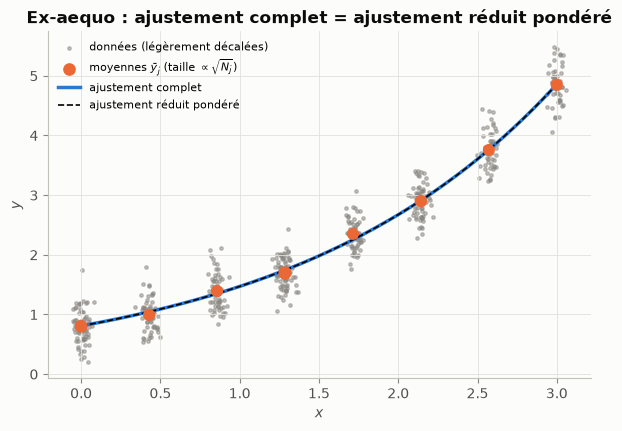

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
tt = np.linspace(0, 3, 200)
ax.scatter(x + 0.03 * rng.normal(size=500), y2, s=6, color=GRAY, alpha=0.5, label="données (légèrement décalées)")
ax.scatter(u[:, 0], ybar2, s=8 * np.sqrt(Nj), color=ORANGE, zorder=3, label="moyennes $\\bar y_j$ (taille $\\propto \\sqrt{N_j}$)")
ax.plot(tt, fit_full.x[0] * np.exp(fit_full.x[1] * tt), color=BLUE, lw=2.5, label="ajustement complet")
ax.plot(tt, fit_red.x[0] * np.exp(fit_red.x[1] * tt), color="k", ls="--", lw=1.2, label="ajustement réduit pondéré")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Ex-aequo : ajustement complet = ajustement réduit pondéré")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** $\sum_{i\in I_j}(y_i - c)^2 = \text{const} + N_j(\bar y_j - c)^2$ : avec des
> ex-aequo, on remplace chaque groupe par sa moyenne, pondérée par son effectif.

## Exercice 2.7 : Estimateurs linéaires en $y$ : biais et variance

**Énoncé (reformulé).** On dispose de $N$ couples $(x_i, y_i)$ i.i.d. tels que
$x_i\sim h(x)$ (densité du plan d'expérience), $y_i = f(x_i) + \varepsilon_i$ ($f$ fonction
de régression), avec $\varepsilon_i$ centrée de variance $\sigma^2$. On considère un
estimateur de $f$ **linéaire en les $y_i$** :
$$\hat f(x_0) = \sum_{i=1}^N\ell_i(x_0;\mathcal X)\,y_i,$$
où les poids $\ell_i(x_0;\mathcal X)$ ne dépendent pas des $y_i$ mais dépendent de toute la
suite $\mathcal X = (x_1, \dots, x_N)$. On note $\mathcal Y = (y_1, \dots, y_N)$.

(a) Montrer que la régression linéaire et les $k$-ppv sont de ce type ; expliciter les poids.

(b) Décomposer l'erreur quadratique **conditionnelle** $E_{\mathcal Y\mid\mathcal X}(f(x_0) - \hat f(x_0))^2$
en biais au carré conditionnel et variance conditionnelle.

(c) Décomposer l'erreur quadratique **non conditionnelle** $E_{\mathcal Y,\mathcal X}(f(x_0) - \hat f(x_0))^2$
en biais au carré et variance.

(d) Établir une relation entre les biais au carré et les variances des deux cas.

### (a) Les poids des deux méthodes

**Régression linéaire.** Avec $\mathbf X$ la matrice $N\times(p+1)$ de lignes $(1, x_i^T)$
et $a_0 = (1, x_0^T)^T$ :
$$\hat f(x_0) = a_0^T\hat\beta = a_0^T(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y = \sum_{i=1}^N\underbrace{\big[\mathbf X(\mathbf X^T\mathbf X)^{-1}a_0\big]_i}_{\ell_i(x_0;\mathcal X)}y_i.$$
Les poids dépendent de tous les $x_i$ (via $\mathbf X$) et de $x_0$, pas des $y_i$.

**$k$ plus proches voisins.**
$$\hat f(x_0) = \frac1k\sum_{x_i\in N_k(x_0)}y_i, \qquad \ell_i(x_0;\mathcal X) = \begin{cases}1/k & \text{si } x_i\in N_k(x_0),\\ 0 & \text{sinon.}\end{cases}$$
Le voisinage $N_k(x_0)$ ne dépend que des positions $x_i$ : les poids ne dépendent pas des $y_i$.

Vérifions numériquement que $\sum_i\ell_iy_i$ redonne bien les prédictions
(fonctions `c2.ols_weights` et `c2.knn_weights`).

In [5]:
Xs = rng.uniform(size=(40, 2))
ys = rng.normal(size=40)
x0 = np.array([0.85, 0.8])
l_ols, l_knn = c2.ols_weights(Xs, x0), c2.knn_weights(Xs, x0, 5)
print("OLS : sum l_i y_i = %.6f ; prédiction directe = %.6f"
      % (l_ols @ ys, c2.least_squares_predict(x0[None], c2.least_squares_fit(Xs, ys))[0]))
print("5-ppv : sum l_i y_i = %.6f ; prédiction directe = %.6f"
      % (l_knn @ ys, c2.knn_regress(Xs, ys, x0[None], 5)[0]))
print("somme des poids : OLS %.4f, 5-ppv %.4f" % (l_ols.sum(), l_knn.sum()))

OLS : sum l_i y_i = 0.151361 ; prédiction directe = 0.151361
5-ppv : sum l_i y_i = 0.542957 ; prédiction directe = 0.542957
somme des poids : OLS 1.0000, 5-ppv 1.0000


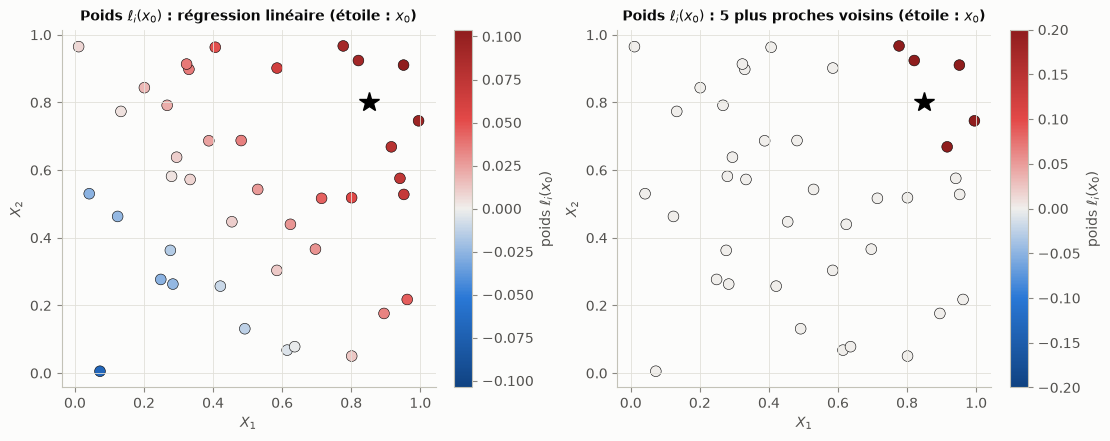

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for ax, l, name in zip(axes, [l_ols, l_knn], ["régression linéaire", "5 plus proches voisins"]):
    lim = np.abs(l).max()
    sc = ax.scatter(Xs[:, 0], Xs[:, 1], c=l, cmap=DIV, vmin=-lim, vmax=lim, s=60, edgecolors="k", linewidths=0.4)
    ax.plot(*x0, "k*", ms=15)
    fig.colorbar(sc, ax=ax, label="poids $\\ell_i(x_0)$")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_title("Poids $\\ell_i(x_0)$ : %s (étoile : $x_0$)" % name, fontsize=10)
plt.show()

Les poids de la régression linéaire sont **non locaux** (et parfois négatifs) : tous
les points comptent ; ceux des $k$-ppv sont locaux et positifs.

### (b) Décomposition conditionnelle à $\mathcal X$

Sachant $\mathcal X$, les poids $\ell_i = \ell_i(x_0;\mathcal X)$ sont des constantes et les
$\varepsilon_i$ restent centrés, indépendants, de variance $\sigma^2$ (indépendance des couples).
Par linéarité de l'espérance :
$$E_{\mathcal Y\mid\mathcal X}\hat f(x_0) = \sum_i\ell_i\,E(y_i\mid\mathcal X) = \sum_i\ell_if(x_i).$$
On écrit $f(x_0) - \hat f(x_0) = \big[f(x_0) - \sum_i\ell_if(x_i)\big] - \sum_i\ell_i\varepsilon_i$ ; le premier
crochet est constant sachant $\mathcal X$ et le second terme est centré, d'où (double produit nul) :
$$E_{\mathcal Y\mid\mathcal X}\big(f(x_0) - \hat f(x_0)\big)^2 = \underbrace{\Big[f(x_0) - \sum_{i}\ell_if(x_i)\Big]^2}_{\mathrm{Biais}^2(\hat f(x_0)\mid\mathcal X)} + \underbrace{\sigma^2\sum_{i}\ell_i^2}_{\mathrm{Var}(\hat f(x_0)\mid\mathcal X)}.$$
La variance vient de $\mathrm{Var}(\sum_i\ell_i\varepsilon_i\mid\mathcal X) = \sum_i\ell_i^2\sigma^2$ (indépendance).

### (c) Décomposition non conditionnelle

Notons $\bar f(x_0) = E_{\mathcal Y,\mathcal X}\hat f(x_0) = E_{\mathcal X}\big[\sum_i\ell_if(x_i)\big]$ (espérance totale).
En ajoutant et retranchant $\bar f(x_0)$ :
$$E_{\mathcal Y,\mathcal X}\big(f(x_0) - \hat f(x_0)\big)^2 = \underbrace{\big[f(x_0) - \bar f(x_0)\big]^2}_{\mathrm{Biais}^2(\hat f(x_0))} + \underbrace{E_{\mathcal Y,\mathcal X}\big(\hat f(x_0) - \bar f(x_0)\big)^2}_{\mathrm{Var}(\hat f(x_0))},$$
le double produit étant nul car $E(\hat f(x_0) - \bar f(x_0)) = 0$ et $f(x_0) - \bar f(x_0)$ est une constante.

On peut expliciter la variance avec la **formule de la variance totale**
$\mathrm{Var}(Z) = E_{\mathcal X}[\mathrm{Var}(Z\mid\mathcal X)] + \mathrm{Var}_{\mathcal X}(E[Z\mid\mathcal X])$ :
$$\mathrm{Var}(\hat f(x_0)) = \sigma^2E_{\mathcal X}\Big[\sum_i\ell_i^2\Big] + \mathrm{Var}_{\mathcal X}\Big(\sum_i\ell_if(x_i)\Big).$$

### (d) Relations entre les deux décompositions

Notons $B(\mathcal X) = f(x_0) - \sum_i\ell_if(x_i)$ le biais conditionnel ; alors
$E_{\mathcal X}B(\mathcal X) = f(x_0) - \bar f(x_0)$ est le biais non conditionnel. Comme
$E[B^2] = (E B)^2 + \mathrm{Var}(B)$ et $\mathrm{Var}_{\mathcal X}(B) = \mathrm{Var}_{\mathcal X}(\sum_i\ell_if(x_i))$ :
$$E_{\mathcal X}\big[\mathrm{Biais}^2(\hat f\mid\mathcal X)\big] = \mathrm{Biais}^2(\hat f) + \mathrm{Var}_{\mathcal X}\Big(\sum_i\ell_if(x_i)\Big),$$
$$\mathrm{Var}(\hat f) = E_{\mathcal X}\big[\mathrm{Var}(\hat f\mid\mathcal X)\big] + \mathrm{Var}_{\mathcal X}\Big(\sum_i\ell_if(x_i)\Big).$$

Le terme $V = \mathrm{Var}_{\mathcal X}(\sum_i\ell_if(x_i))$ - la variabilité du biais conditionnel
due au tirage des $x_i$ - passe du **biais** (cas conditionnel moyenné) à la **variance**
(cas non conditionnel). En conséquence :

- le biais au carré moyen conditionnel **majore** le biais au carré non conditionnel ;
- la variance non conditionnelle **majore** la variance conditionnelle moyenne ;
- les sommes sont égales : $E_{\mathcal X}[\text{MSE conditionnelle}] = \text{MSE non conditionnelle}$
  (espérance totale). $\blacksquare$

**Vérification numérique.** Plan d'expérience $h = \mathcal U(0, 1)$, $f(x) = \sin(2\pi x)$,
$\sigma = 0{,}3$, $N = 50$, $x_0 = 0{,}3$. Pour chaque tirage de $\mathcal X$, les quantités
conditionnelles se calculent **exactement** à partir des poids ; on moyenne ensuite sur
20 000 tirages de $\mathcal X$. On contrôle aussi la MSE par une simulation complète de $(\mathcal X, \mathcal Y)$.

In [7]:
f = lambda t: np.sin(2 * np.pi * t)
sigma, N, x0, R = 0.3, 50, 0.3, 20000
rows = {}
for name, wfun in [("linéaire", lambda X: c2.ols_weights(X, np.array([x0]))),
                   ("10-ppv", lambda X: c2.knn_weights(X, np.array([x0]), 10))]:
    m, B, Vc, mse_full = np.empty(R), np.empty(R), np.empty(R), np.empty(R)
    for r in range(R):
        X = rng.uniform(size=N)
        l = wfun(X)
        m[r] = l @ f(X)                       # E(f_hat | X)
        B[r] = f(x0) - m[r]                   # biais conditionnel
        Vc[r] = sigma ** 2 * l @ l            # variance conditionnelle
        Y = f(X) + sigma * rng.normal(size=N)
        mse_full[r] = (f(x0) - l @ Y) ** 2    # simulation complète
    rows[name] = {
        "E_X[biais² cond.]": np.mean(B ** 2),
        "biais² non cond.": np.mean(B) ** 2,
        "E_X[var cond.]": np.mean(Vc),
        "var non cond.": np.mean(Vc) + m.var(),
        "Var_X(sum l f)": m.var(),
        "MSE (formule)": np.mean(B ** 2) + np.mean(Vc),
        "MSE (simulée)": mse_full.mean(),
    }
pd.DataFrame(rows).round(5)

,linéaire,10-ppv
E_X[biais² cond.],0.32520,0.00903
biais² non cond.,0.31872,0.00568
E_X[var cond.],0.00273,0.00900
var non cond.,0.00922,0.01235
Var_X(sum l f),0.00648,0.00335
MSE (formule),0.32793,0.01803
MSE (simulée),0.32747,0.01808
